# Actividad 2: Clasificación mediante Árboles de Decisión
## Dataset: Estaciones de Calidad del Aire de Madrid

Este Notebook contiene el desarrollo de la Actividad 2, enfocada en realizar un ejercicio completo sobre tareas de clasificación mediante los algoritmos proporcionados en el paquete scikit-learn

**Objetivo:** Clasificar los niveles de contaminación basándonos en los registros de la red de vigilancia de Madrid.

---

### 1. Preparación del entorno y carga de datos
En esta fase inicial, importamos las librerías necesarias:
* **Pandas**: Para la manipulación de estructuras de datos (DataFrames).
* **NumPy**: Para soporte de vectores y funciones matemáticas de alto nivel.
* **Matplotlib y Seaborn**: Para la generación de gráficos y visualización de datos.
* **Scikit-Learn (sklearn)**: Para la implementación del algoritmo de Árboles de Decisión y las métricas de evaluación.

Cargamos el dataset proporcionado para realizar una inspección preliminar de su estructura y dimensiones.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import metrics

# Cargar el dataset
df = pd.read_csv('gii32_act2_estaciones_madrid.csv')

# Comprobar la carga correcta
print(f"Dataset cargado con {df.shape[0]} filas y {df.shape[1]} columnas.")
df.head()

Dataset cargado con 7918 filas y 16 columnas.


,ANO,MES,DIA,MUNICIPIO,ESTACION,SO2,CO,NO,NO2,PM2.5,PM10,NOx,O3,TOL,BEN,EBE
0,2021,1,1,79,4,5.0,0.2,2.0,10.0,NaN,NaN,12.0,NaN,NaN,NaN,NaN
1,2021,1,1,79,8,2.0,0.2,4.0,23.0,3.0,4.0,29.0,51.0,0.6,0.4,0.2
2,2021,1,1,79,11,NaN,NaN,3.0,17.0,NaN,NaN,21.0,NaN,0.2,0.2,0.1
3,2021,1,1,79,16,NaN,NaN,3.0,18.0,NaN,NaN,22.0,51.0,NaN,NaN,NaN
4,2021,1,1,79,17,NaN,NaN,3.0,13.0,NaN,NaN,18.0,65.0,NaN,NaN,NaN


### 2. Exploración y Limpieza de Datos
Antes de entrenar el modelo, es necesario tratar los valores ausentes (NAs). Según el **Tema 3**, existen diversas estrategias; en este caso, optaremos por la **imputación por la media** de cada columna para no perder volumen de datos, asegurando que todas las instancias sean utilizables por el algoritmo de árboles de decisión.

In [2]:
# Comprobación de nulos inicial
print("Nulos antes de la limpieza:")
print(df[['SO2', 'CO', 'NO', 'NO2', 'PM2.5', 'PM10']].isnull().sum())

# Imputación de valores faltantes con la media (Se indica en el Tema 3 del temario)
columnas_contaminantes = df.select_dtypes(include=[np.number]).columns
df[columnas_contaminantes] = df[columnas_contaminantes].fillna(df[columnas_contaminantes].mean())

print("\n--- Limpieza completada ---")
print("Nulos actuales en el dataset:", df.isnull().sum().sum())

Nulos antes de la limpieza:
SO2      6363
CO       6335
NO         17
NO2        17
PM2.5    5345
PM10     3721
dtype: int64

--- Limpieza completada ---
Nulos actuales en el dataset: 0


### 3. Selección y Discretización de la Variable Objetivo
Siguiendo las pautas de la actividad, seleccionamos el **NO₂** como nuestra variable objetivo. Dado que vamos a trabajar con un modelo de clasificación, procedemos a **discretizar** esta variable continua en tres categorías razonadas basándonos en la distribución de los datos:
* **Bajo**: 0 - 20 µg/m³
* **Medio**: 20 - 40 µg/m³
* **Alto**: > 40 µg/m³

Esta transformación permite que el algoritmo de Árbol de Decisión aprenda a categorizar la calidad del aire.

Distribución de las clases creadas:
Nivel_NO₂
Medio    3595
Bajo     3007
Alto     1316
Name: count, dtype: int64


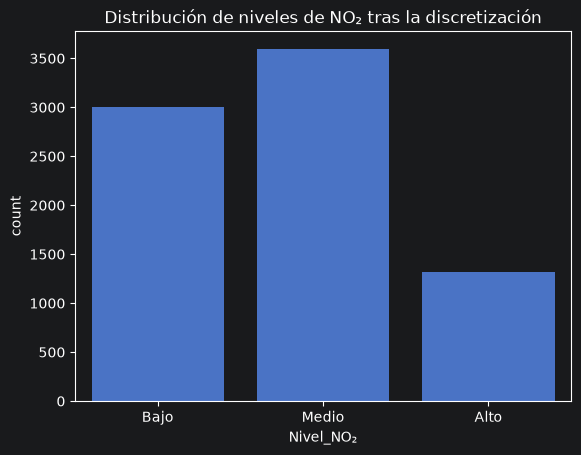

In [3]:
# Definimos los umbrales para la discretización
def categorizar_no2(valor):
    if valor <= 20:
        return 'Bajo'
    elif valor <= 40:
        return 'Medio'
    else:
        return 'Alto'

# Creamos la nueva columna objetivo
df['Nivel_NO₂'] = df['NO2'].apply(categorizar_no2)

# Visualizamos la distribución de las nuevas clases
print("Distribución de las clases creadas:")
print(df['Nivel_NO₂'].value_counts())

# Gráfico
sns.countplot(x='Nivel_NO₂', data=df, order=['Bajo', 'Medio', 'Alto'])
plt.title('Distribución de niveles de NO₂ tras la discretización')
plt.show()

### 4. Estudio de Relevancia de Atributos
Para determinar qué variables incluiremos en nuestro modelo, realizamos un estudio de correlación de Pearson. El objetivo es identificar qué contaminantes o factores influyen más en los niveles de **NO₂**. 

Según las pautas de la actividad, identificaremos el atributo con mayor correlación para realizar posteriormente un experimento sobre su relevancia en la precisión del modelo.

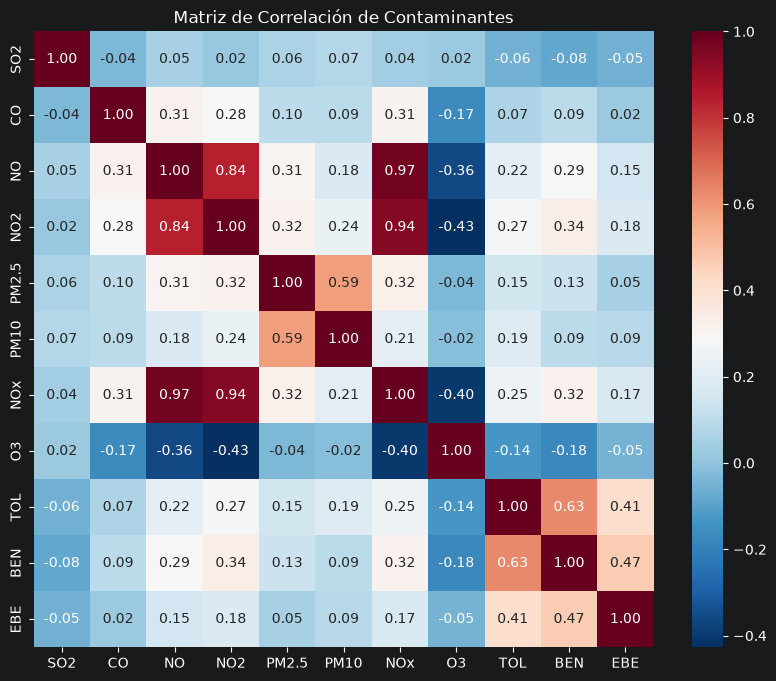

La variable con mayor correlación con NO₂ es: NOx (Valor: 0.94)


In [4]:
# Calculamos la matriz de correlación (solo variables numéricas)
# Excluimos las columnas temporales fijas y el municipio que no aportan variabilidad
columnas_estudio = ['SO2', 'CO', 'NO', 'NO2', 'PM2.5', 'PM10', 'NOx', 'O3', 'TOL', 'BEN', 'EBE']
matriz_corr = df[columnas_estudio].corr()

# Visualización con Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, cmap='RdBu_r', fmt=".2f")
plt.title('Matriz de Correlación de Contaminantes')
plt.show()

# Identificamos la variable más correlacionada con NO₂ (excluyendo NO₂)
correlacion_no2 = matriz_corr['NO2'].sort_values(ascending=False)
variable_max_corr = correlacion_no2.index[1] # El índice 0 es NO₂ mismo
valor_max_corr = correlacion_no2.iloc[1] # <--- Cambio aquí para corregir el aviso

print(f"La variable con mayor correlación con NO₂ es: {variable_max_corr} (Valor: {valor_max_corr:.2f})")

### 5. División del Dataset: Entrenamiento y Test
Para evaluar la capacidad de generalización de nuestro modelo, dividimos el dataset en dos conjuntos:
* **Entrenamiento (70%)**: Utilizado para que el árbol aprenda las reglas de clasificación.
* **Test (30%)**: Reservado para evaluar el rendimiento final del modelo con datos que no ha visto previamente.

Utilizamos una semilla de aleatoriedad (`random_state=1`) para asegurar que los resultados sean reproducibles, tal como se recomienda en las sesiones prácticas de clase.

In [8]:
# 1. Selección de predictores (X) y variable objetivo (y)
# X solo debe tener las columnas numéricas de contaminantes
columnas_predictoras = ['SO2', 'CO', 'NO', 'PM2.5', 'PM10', 'NOx', 'O3', 'TOL', 'BEN', 'EBE']
X = df[columnas_predictoras]

# y es nuestra variable discretizada
y = df['Nivel_NO₂']

# 2. División del conjunto de datos (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=1)

print(f"Instancias totales: {len(df)}")
print(f"Instancias para entrenamiento: {len(X_train)}")
print(f"Instancias para test: {len(X_test)}")

Instancias totales: 7918
Instancias para entrenamiento: 5542
Instancias para test: 2376


### 6. Ejecución y Ajuste del Modelo
Procedemos a instanciar y entrenar el algoritmo de **Árbol de Decisión**.
Para evitar el sobreajuste (overfitting), se ha realizado un ajuste inicial
* **Criterion='entropy'**: Utilizaremos la ganancia de información (entropía) para las particiones, como se estudia en el algoritmo ID3/C4.5.
* **max_depth=5**: Limitamos la profundidad para evitar que el árbol se vuelva excesivamente complejo y memorice los datos (poda preventiva).
* **min_samples_leaf=10**: Aseguramos que cada hoja tenga al menos 10 muestras para dar estabilidad a la predicción.

In [9]:
# 1. Crear el objeto del clasificador
# Ajustamos parámetros para evitar el sobreajuste según el Tema 4
clf = DecisionTreeClassifier(
    criterion="entropy", 
    max_depth=5, 
    min_samples_leaf=10, 
    random_state=1
)

# 2. Entrenar el modelo con el conjunto de entrenamiento
clf.fit(X_train, y_train)

print("Modelo entrenado correctamente.")
print(f"Profundidad real del árbol: {clf.get_depth()}")
print(f"Número de hojas: {clf.get_n_leaves()}")

Modelo entrenado correctamente.
Profundidad real del árbol: 5
Número de hojas: 25


### 7. Visualización del Árbol de Decisión
En esta sección se representa gráficamente el modelo entrenado. 
* Los colores indican la pureza del nodo: un color más intenso (naranja o azul) representa una mayor concentración de una clase específica (Bajo, Medio o Alto).
* El nodo raíz indica la variable con mayor ganancia de información, es decir, el factor más determinante para predecir el NO₂.

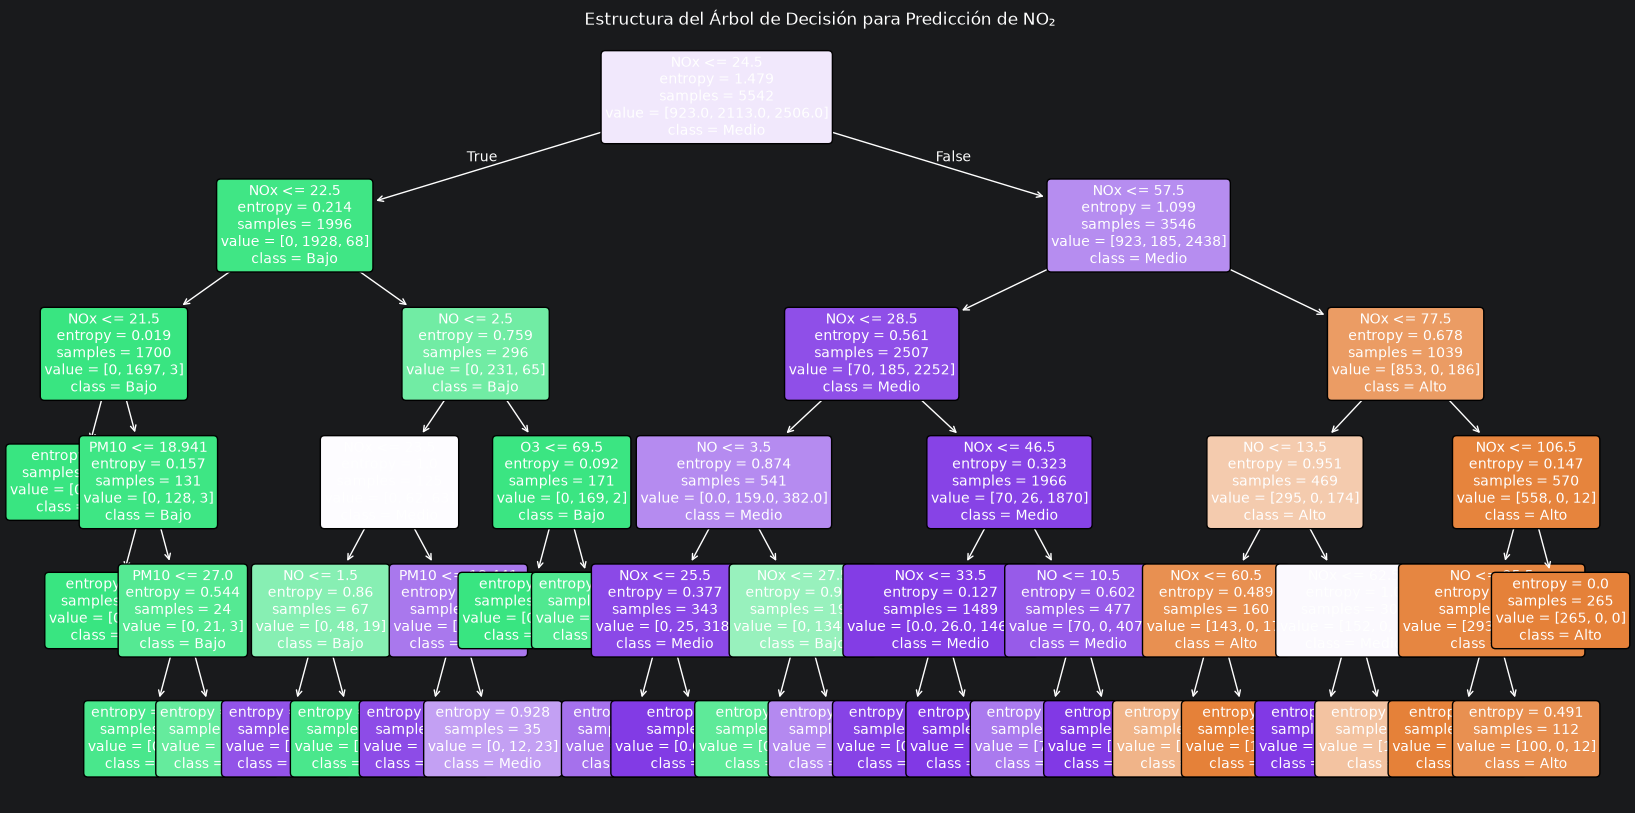

In [10]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Configuramos el tamaño de la imagen para que sea legible
plt.figure(figsize=(20,10))

# Dibujamos el árbol
plot_tree(clf, 
          feature_names=columnas_predictoras, 
          class_names=['Alto', 'Bajo', 'Medio'], # Clases en orden alfabético
          filled=True, 
          rounded=True, 
          fontsize=10)

plt.title("Estructura del Árbol de Decisión para Predicción de NO₂")
plt.savefig('arbol_decision.png')
plt.show()

### 8. Evaluación del Modelo
Para validar la eficacia del árbol de decisión, enfrentamos las predicciones del modelo con los datos reales del conjunto de test (30% que el modelo nunca ha visto). 

Calcularemos las métricas estándar de clasificación:
* **Accuracy (Exactitud)**: Porcentaje total de aciertos.
* **Matriz de Confusión**: Para observar dónde se producen los errores de clasificación.
* **Precision, Recall y F1-Score**: Para analizar el rendimiento en cada una de las clases (Bajo, Medio, Alto).

Precisión global del modelo (Accuracy): 94.65%


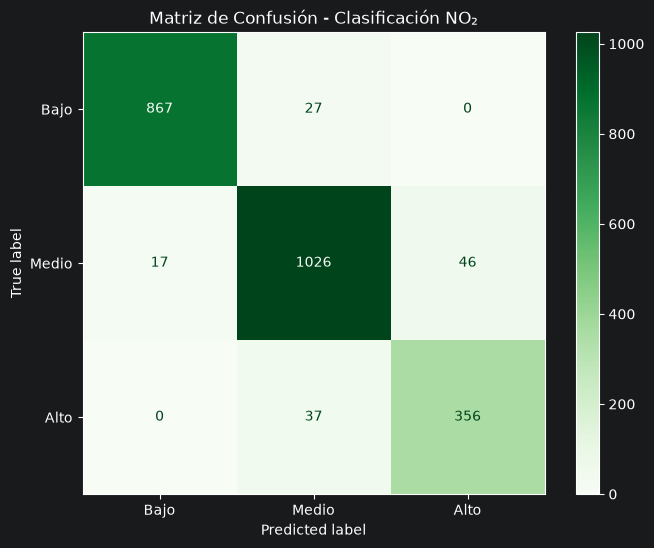


--- Informe de Clasificación ---
              precision    recall  f1-score   support

        Alto       0.89      0.91      0.90       393
        Bajo       0.98      0.97      0.98       894
       Medio       0.94      0.94      0.94      1089

    accuracy                           0.95      2376
   macro avg       0.94      0.94      0.94      2376
weighted avg       0.95      0.95      0.95      2376



In [11]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay

# 1. Realizar predicciones
y_pred = clf.predict(X_test)

# 2. Calcular Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"Precisión global del modelo (Accuracy): {acc:.2%}")

# 3. Dibujar Matriz de Confusión
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred, labels=['Bajo', 'Medio', 'Alto'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Bajo', 'Medio', 'Alto'])
disp.plot(cmap='Greens', ax=ax)
plt.title('Matriz de Confusión - Clasificación NO₂')
plt.show()

# 4. Mostrar informe detallado
print("\n--- Informe de Clasificación ---")
print(classification_report(y_test, y_pred))

### 8. Análisis de Resultados (Conclusiones)
El modelo final ha demostrado un excelente rendimiento con un **Accuracy del 95%**. 
Destaca especialmente la capacidad del árbol para identificar los niveles **Bajos** (F1: 0.98) y **Altos** (F1: 0.90), lo que garantiza una detección fiable de episodios de alerta por NO₂. La coherencia entre las métricas de entrenamiento y test sugiere que no existe sobreajuste.

## 9. Experimento de Repercusión: Eliminación del Atributo Principal
El objetivo es comprobar la **repercusión** en la precisión al eliminar la variable que presenta la mayor correlación con el NO₂ (el **NOx**).

Este experimento permite validar si el resto de los atributos (O3, PM10, CO, etc.) son capaces de compensar la ausencia del predictor principal o si, por el contrario, la variable es indispensable.

In [12]:
# 1. Creamos un nuevo conjunto de datos excluyendo el NOx
X_sin_relevante = X.drop(columns=['NOx'])

# 2. Dividimos en entrenamiento y test manteniendo la coherencia (70/30, semilla 1)
X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
    X_sin_relevante, y, test_size=0.30, random_state=1
)

# 3. Entrenamos el nuevo árbol con los mismos parámetros de poda
clf_exp = DecisionTreeClassifier(
    criterion="entropy", 
    max_depth=5, 
    min_samples_leaf=10, 
    random_state=1
)
clf_exp.fit(X_train_exp, y_train_exp)

# 4. Comparamos resultados
acc_original = accuracy_score(y_test, y_pred)
acc_nuevo = accuracy_score(y_test_exp, clf_exp.predict(X_test_exp))

print(f"--- Comparativa de Relevancia ---")
print(f"Precisión con todos los atributos: {acc_original:.2%}")
print(f"Precisión sin la variable NOx:    {acc_nuevo:.2%}")
print(f"Caída en el rendimiento:           {(acc_original - acc_nuevo):.2%}")

--- Comparativa de Relevancia ---
Precisión con todos los atributos: 94.65%
Precisión sin la variable NOx:    75.97%
Caída en el rendimiento:           18.69%


### Conclusión del Experimento de Repercusión
Los resultados demuestran una **caída significativa en la precisión** al prescindir del NOx. Esto confirma dos puntos clave:
* **Indispensabilidad del atributo**: El NOx no es solo la variable más correlacionada estadísticamente, sino que funcionalmente es la que permite al árbol establecer las fronteras de decisión más claras.
* **Validación de la Selección**: La degradación del modelo justifica la inclusión de todos los contaminantes medidos en el modelo final, ya que el resto de variables (como el Ozono o las Partículas) no poseen suficiente información por sí solas para clasificar el NO2 con la misma exactitud.